## 1. Importación de librerías

Se utilizarán herramientas de `scikit-learn` para cargar el dataset, dividir los datos, estandarizar las variables, entrenar los clasificadores y calcular las métricas de desempeño.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
N_SPLITS = 4


## 2. Carga y exploración del dataset

El dataset `digits` contiene imágenes de dígitos escritos a mano. Cada imagen se representa mediante 64 características, correspondientes a una imagen de 8 × 8 píxeles.


In [2]:
digits = load_digits()

X = digits.data
y = digits.target

print("Número de muestras:", X.shape[0])
print("Número de características:", X.shape[1])
print("Clases:", np.unique(y))


Número de muestras: 1797
Número de características: 64
Clases: [0 1 2 3 4 5 6 7 8 9]


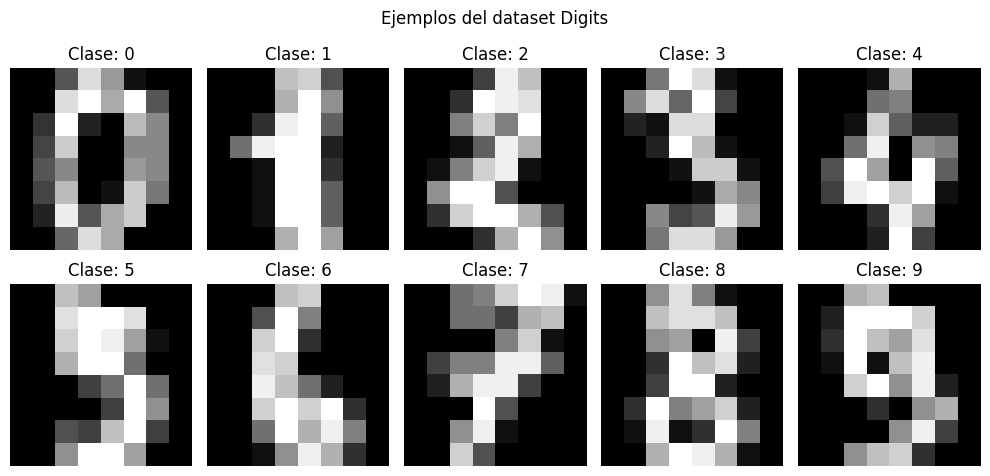

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for ax, image, label in zip(axes.ravel(), digits.images[:10], digits.target[:10]):
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Clase: {label}")
    ax.axis("off")

plt.suptitle("Ejemplos del dataset Digits")
plt.tight_layout()
plt.show()


## 3. División del dataset

Se separan los datos en:

- **80 % para entrenamiento:** se utiliza en la validación cruzada y para entrenar el modelo final.
- **20 % para prueba:** se reserva para la evaluación final.

Se utiliza `stratify=y` para conservar una distribución similar de las clases en ambos conjuntos.


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Datos de entrenamiento: {X_train.shape[0]}")
print(f"Datos de prueba: {X_test.shape[0]}")


Datos de entrenamiento: 1437
Datos de prueba: 360


## 4. Validación cruzada y métricas

Se utiliza `StratifiedKFold` con cuatro particiones. La estratificación ayuda a mantener la proporción de las clases en cada partición.

Las métricas usadas son:

- **Accuracy:** proporción de predicciones correctas.
- **Precision macro:** promedio de la precisión de todas las clases.
- **Recall macro:** promedio de la capacidad de recuperar correctamente las muestras de cada clase.
- **F1 macro:** promedio de la medida F1 de todas las clases.

El parámetro se seleccionará usando el **F1 macro promedio**, porque considera conjuntamente Precision y Recall para todas las clases.


In [5]:
cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

from sklearn.metrics import make_scorer

scoring = {
    "accuracy": "accuracy",
    "precision_macro": make_scorer(
        precision_score, average="macro", zero_division=0
    ),
    "recall_macro": make_scorer(
        recall_score, average="macro", zero_division=0
    ),
    "f1_macro": make_scorer(
        f1_score, average="macro", zero_division=0
    )
}


# Parte A. Clasificador KNN

## 5. Evaluación de diferentes valores de K

Se utiliza la distancia euclidiana y los pesos ponderados por distancia:

- `metric="euclidean"`
- `weights="distance"`

La estandarización se incluye dentro de un `Pipeline` para que se ajuste únicamente con los datos de cada partición de entrenamiento y no se produzca fuga de información.


In [6]:
valores_k = np.arange(1, 31, 2)
resultados_knn = []

for k in valores_k:
    modelo_knn = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(
            n_neighbors=int(k),
            weights="distance",
            metric="euclidean"
        ))
    ])

    resultados = cross_validate(
        modelo_knn,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    resultados_knn.append({
        "K": k,
        "Accuracy": resultados["test_accuracy"].mean(),
        "Precision": resultados["test_precision_macro"].mean(),
        "Recall": resultados["test_recall_macro"].mean(),
        "F1": resultados["test_f1_macro"].mean()
    })

resultados_knn = pd.DataFrame(resultados_knn)
resultados_knn


,K,Accuracy,Precision,Recall,F1
0,1,0.968676,0.969722,0.968505,0.968471
1,3,0.971466,0.972108,0.971342,0.971329
2,5,0.978430,0.979013,0.978407,0.978353
3,7,0.975646,0.976343,0.975489,0.975522
4,9,0.971474,0.972268,0.971242,0.971312
5,11,0.968692,0.969553,0.968523,0.968528
6,13,0.963821,0.964985,0.963580,0.963525
7,15,0.958948,0.960032,0.958739,0.958618
8,17,0.956167,0.957370,0.955841,0.955726
9,19,0.954082,0.955542,0.953738,0.953694


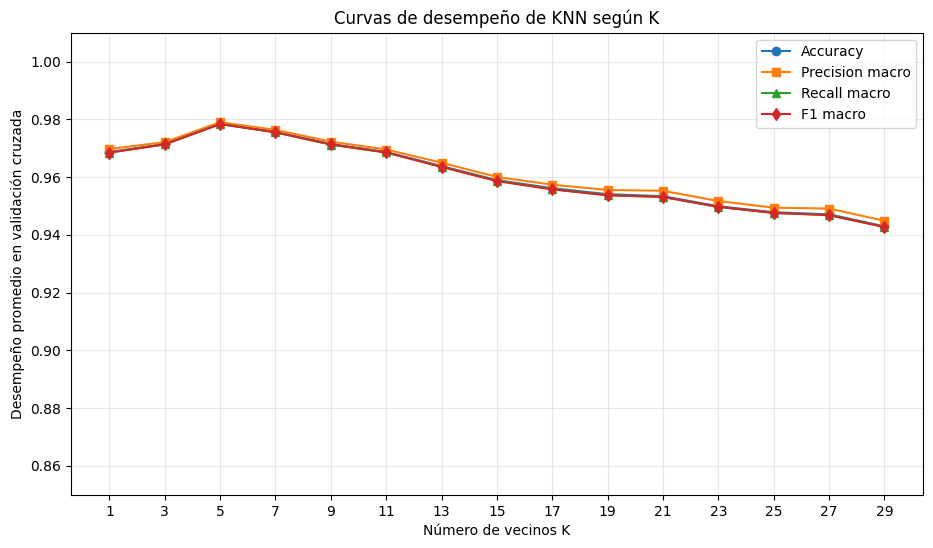

In [7]:
plt.figure(figsize=(11, 6))

plt.plot(resultados_knn["K"], resultados_knn["Accuracy"], marker="o", label="Accuracy")
plt.plot(resultados_knn["K"], resultados_knn["Precision"], marker="s", label="Precision macro")
plt.plot(resultados_knn["K"], resultados_knn["Recall"], marker="^", label="Recall macro")
plt.plot(resultados_knn["K"], resultados_knn["F1"], marker="d", label="F1 macro")

plt.title("Curvas de desempeño de KNN según K")
plt.xlabel("Número de vecinos K")
plt.ylabel("Desempeño promedio en validación cruzada")
plt.xticks(valores_k)
plt.ylim(0.85, 1.01)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## 6. Selección del mejor K

Se selecciona el valor de `K` que obtiene el mayor F1 macro promedio. En caso de empate, se utiliza el Accuracy como segundo criterio.


In [8]:
mejor_knn = resultados_knn.sort_values(
    by=["F1", "Accuracy"],
    ascending=False
).iloc[0]

mejor_k = int(mejor_knn["K"])

print("Mejor K:", mejor_k)
print(mejor_knn)


Mejor K: 5
K            5.000000
Accuracy     0.978430
Precision    0.979013
Recall       0.978407
F1           0.978353
Name: 2, dtype: float64


# Parte B. Clasificador RNN

## 7. Evaluación de diferentes valores de R

En este trabajo, RNN significa **Radius Nearest Neighbors**, es decir, vecinos más cercanos dentro de un radio.

Se utiliza:

- `radius=R`
- Distancia euclidiana.
- Pesos ponderados por distancia.
- `outlier_label="most_frequent"` para asignar una clase cuando una muestra no tenga vecinos dentro del radio.

El rango de radios se evalúa mediante validación cruzada con las mismas cuatro particiones.


In [9]:
valores_r = np.arange(2.0, 15.5, 0.5)
resultados_rnn = []

for radio in valores_r:
    modelo_rnn = Pipeline([
        ("scaler", StandardScaler()),
        ("rnn", RadiusNeighborsClassifier(
            radius=float(radio),
            weights="distance",
            metric="euclidean",
            outlier_label="most_frequent"
        ))
    ])

    resultados = cross_validate(
        modelo_rnn,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    resultados_rnn.append({
        "R": radio,
        "Accuracy": resultados["test_accuracy"].mean(),
        "Precision": resultados["test_precision_macro"].mean(),
        "Recall": resultados["test_recall_macro"].mean(),
        "F1": resultados["test_f1_macro"].mean()
    })

resultados_rnn = pd.DataFrame(resultados_rnn)
resultados_rnn


,R,Accuracy,Precision,Recall,F1
0,2.0,0.104387,0.110189,0.102817,0.023973
1,2.5,0.140570,0.510572,0.139075,0.090534
2,3.0,0.259569,0.887076,0.258090,0.271059
3,3.5,0.441889,0.915416,0.440432,0.493550
4,4.0,0.647870,0.918829,0.647104,0.702279
5,4.5,0.801664,0.928141,0.800957,0.832537
6,5.0,0.882393,0.938381,0.881894,0.895665
7,5.5,0.917197,0.946895,0.916904,0.923971
8,6.0,0.934585,0.951718,0.934325,0.938126
9,6.5,0.935283,0.947304,0.934999,0.937455


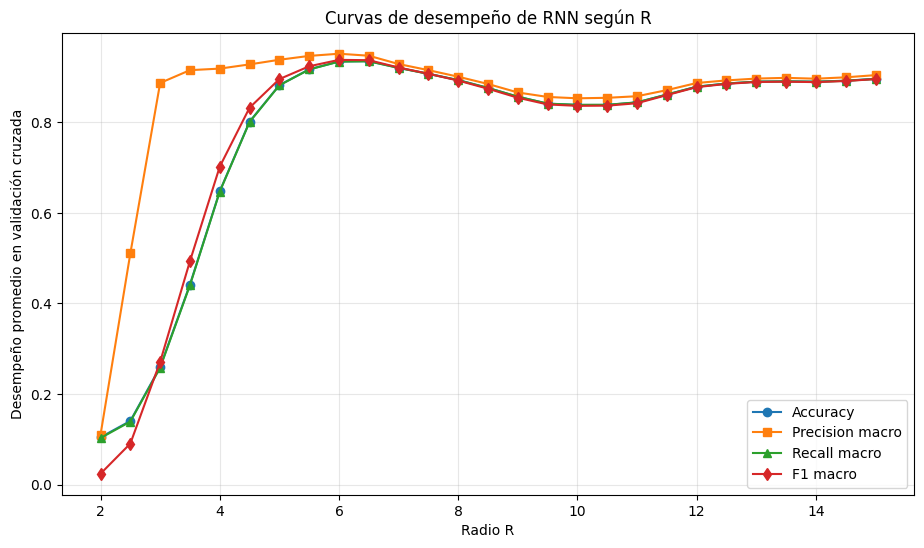

In [10]:
plt.figure(figsize=(11, 6))

plt.plot(resultados_rnn["R"], resultados_rnn["Accuracy"], marker="o", label="Accuracy")
plt.plot(resultados_rnn["R"], resultados_rnn["Precision"], marker="s", label="Precision macro")
plt.plot(resultados_rnn["R"], resultados_rnn["Recall"], marker="^", label="Recall macro")
plt.plot(resultados_rnn["R"], resultados_rnn["F1"], marker="d", label="F1 macro")

plt.title("Curvas de desempeño de RNN según R")
plt.xlabel("Radio R")
plt.ylabel("Desempeño promedio en validación cruzada")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## 8. Selección del mejor R

Se selecciona el valor de `R` que obtiene el mayor F1 macro promedio. En caso de empate, se utiliza el Accuracy como segundo criterio.


In [11]:
mejor_rnn = resultados_rnn.sort_values(
    by=["F1", "Accuracy"],
    ascending=False
).iloc[0]

mejor_r = float(mejor_rnn["R"])

print("Mejor R:", mejor_r)
print(mejor_rnn)


Mejor R: 6.0
R            6.000000
Accuracy     0.934585
Precision    0.951718
Recall       0.934325
F1           0.938126
Name: 8, dtype: float64


# Parte C. Evaluación final sobre el conjunto de prueba

Después de seleccionar `K` y `R` con validación cruzada, se entrenan ambos modelos usando todo el conjunto de entrenamiento y se evalúan una sola vez sobre el conjunto de prueba.


In [12]:
modelo_knn_final = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(
        n_neighbors=mejor_k,
        weights="distance",
        metric="euclidean"
    ))
])

modelo_rnn_final = Pipeline([
    ("scaler", StandardScaler()),
    ("rnn", RadiusNeighborsClassifier(
        radius=mejor_r,
        weights="distance",
        metric="euclidean",
        outlier_label="most_frequent"
    ))
])

modelo_knn_final.fit(X_train, y_train)
modelo_rnn_final.fit(X_train, y_train)

pred_knn = modelo_knn_final.predict(X_test)
pred_rnn = modelo_rnn_final.predict(X_test)


In [13]:
def evaluar_modelo(nombre, y_real, y_pred):
    resultados = {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision macro": precision_score(y_real, y_pred, average="macro", zero_division=0),
        "Recall macro": recall_score(y_real, y_pred, average="macro", zero_division=0),
        "F1 macro": f1_score(y_real, y_pred, average="macro", zero_division=0)
    }

    print(f"\n{'=' * 60}")
    print(nombre)
    print(f"{'=' * 60}")
    print(pd.Series(resultados))
    print("\nReporte de clasificación:")
    print(classification_report(y_real, y_pred, zero_division=0))

    return resultados

evaluacion_knn = evaluar_modelo("KNN", y_test, pred_knn)
evaluacion_rnn = evaluar_modelo("RNN", y_test, pred_rnn)

comparacion_final = pd.DataFrame([evaluacion_knn, evaluacion_rnn])
comparacion_final



KNN
Modelo                  KNN
Accuracy           0.966667
Precision macro    0.967292
Recall macro       0.966424
F1 macro           0.966143
dtype: object

Reporte de clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.92      0.97      0.95        36
           2       0.95      1.00      0.97        35
           3       1.00      1.00      1.00        37
           4       0.97      0.94      0.96        36
           5       1.00      0.97      0.99        37
           6       0.97      1.00      0.99        36
           7       0.92      1.00      0.96        36
           8       0.97      0.89      0.93        35
           9       0.97      0.89      0.93        36

    accuracy                           0.97       360
   macro avg       0.97      0.97      0.97       360
weighted avg       0.97      0.97      0.97       360


RNN
Modelo                  RNN
Accuracy           0.9

,Modelo,Accuracy,Precision macro,Recall macro,F1 macro
0,KNN,0.966667,0.967292,0.966424,0.966143
1,RNN,0.938889,0.954214,0.938329,0.941139


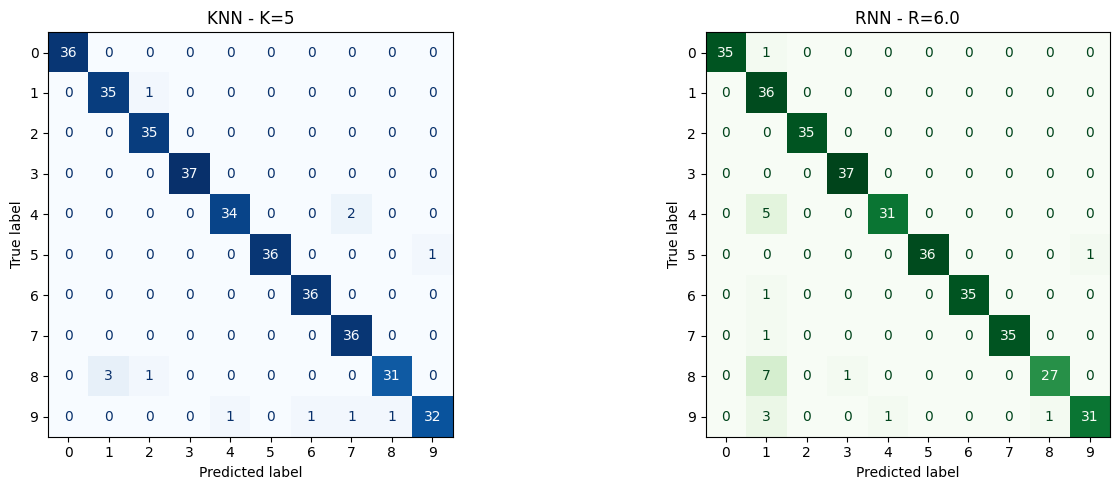

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_knn,
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)
axes[0].set_title(f"KNN - K={mejor_k}")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_rnn,
    ax=axes[1],
    cmap="Greens",
    colorbar=False
)
axes[1].set_title(f"RNN - R={mejor_r}")

plt.tight_layout()
plt.show()


# 9. Conclusiones

Completa las conclusiones después de ejecutar todas las celdas:

1. El valor seleccionado de `K` fue el que obtuvo el mayor F1 macro promedio durante la validación cruzada.
2. El valor seleccionado de `R` fue el que obtuvo el mayor F1 macro promedio durante la validación cruzada.
3. Las curvas permiten observar cómo cambia el desempeño al modificar `K` o `R`.
4. La comparación final debe realizarse con las métricas calculadas sobre el conjunto de prueba, que no participó en la selección de los parámetros.
5. No se debe afirmar que un modelo es mejor únicamente por Accuracy; también deben revisarse Precision, Recall y F1 macro.
